## CLIPScope

Based on original work by Hao Fu, Naman Patel, Prashanth Krishnamurthy and Farshad Khorrami

In [1]:
from pathlib import Path
import numpy as np
import torch
import clip
from torchvision.datasets import CIFAR10, CIFAR100, SVHN, EuroSAT, FashionMNIST, MNIST, KMNIST

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = Path.cwd()

def load_clip(name="ViT-B/16"):
    model, preprocess = clip.load(name, DEVICE)
    model.eval()
    return model, preprocess

@torch.no_grad()
def encode_texts(model, prompts, batch_size=256):
    """L2-normalised CLIP text features, computed in batches (CPU tensor out)."""
    feats = []
    for s in range(0, len(prompts), batch_size):
        tokens = clip.tokenize(prompts[s:s+batch_size], truncate=True).to(DEVICE)
        f = model.encode_text(tokens).float()
        f /= f.norm(dim=-1, keepdim=True)
        feats.append(f.cpu())
    return torch.cat(feats)

def get_dataset(name, root="data"):
    """Return a torchvision-style dataset (test split, downloaded if missing)."""
    n = name.lower()
    if n == "cifar100":
        return CIFAR100(root, train=False, download=True)
    if n == "cifar10":
        return CIFAR10(root, train=False, download=True)
    if n == "svhn":
        return SVHN(root, split="test", download=True)
    if n == "eurosat":
        return EuroSAT(root, download=True)
    if n == "fashionmnist":
        return FashionMNIST(root, train=False, download=True)
    if n == "mnist":
        return MNIST(root, train=False, download=True)
    if n == "kmnist":
        return KMNIST(root, train=False, download=True)
    raise ValueError(f"Unknown dataset: {name}")

def class_names(x):
    """x: dataset name or dataset object. ImageNetV2 uses imagenet_class_clean.npy."""
    if isinstance(x, str):
        if x.lower() == "imagenetv2":
            return [str(c) for c in np.load(ROOT / "imagenet_class_clean.npy").tolist()]
        x = get_dataset(x)
    return [c.replace("_", " ").lower() for c in x.classes]

In [4]:
import math
import numpy as np
import torch
import nltk
from nltk.corpus import wordnet as wn

def load_nouns():
    path = ROOT / "nouns.pt"
    if path.exists():
        nouns = torch.load(path, weights_only=False)
        print(f"Loaded {len(nouns)} nouns from {path}")
    else:
        nltk.download("wordnet", quiet=True)
        nouns = set()
        for syn in wn.all_synsets("n"):
            for lemma in syn.lemma_names():
                if lemma.isalpha() and lemma.islower():
                    nouns.add(lemma)
        nouns = sorted(nouns)
        torch.save(nouns, path)
        print(f"Built {len(nouns)} WordNet nouns -> {path}")
    return [str(n).replace("_", " ") for n in nouns]

def sort_nouns(id, model_name, eta, drop_id_names=False):
    id_classes = class_names(id)
    nouns = np.array(load_nouns())

    if drop_id_names:
        nouns = np.array([n for n in nouns if n not in set(id_classes)])

    model, preprocess = load_clip(model_name)
    text_features = encode_texts(model, [f"a photo of a {c}" for c in id_classes])

    percentile = max(1, math.ceil(len(id_classes) * eta))
    print(f"ID classes: {len(id_classes)} -> percentile index = {percentile}")

    scores = []
    for s in range(0, len(nouns), 1024):
        sample_features = encode_texts(model, [f"a photo of a {w}" for w in nouns[s:s+1024]])
        similarity = -(sample_features @ text_features.T)
        value, index = torch.kthvalue(similarity, percentile, dim=1)
        scores.append(-value.numpy())
        print(f"  {min(s+1024, len(nouns))}/{len(nouns)}", end="\r")

    scores = np.concatenate(scores).astype(np.float32)
    sorted_indices = np.argsort(scores)
    sorted_nouns = [str(nouns[i]) for i in sorted_indices]

    torch.save(sorted_nouns, ROOT / f"sorted_nouns_{id}.pt")

    print("\nTotal nouns:", len(sorted_nouns))
    print("Lowest-ranked nouns:", sorted_nouns[:10])
    print("Highest-ranked nouns:", sorted_nouns[-10:])
    return sorted_nouns

In [5]:
sorted_nouns = sort_nouns(
    id="cifar100",
    model_name="ViT-B/16",
    eta=0.05,
    drop_id_names=False
)

C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Loaded 41492 nouns from c:\Users\achin\Documents\Semester 5 Modules\EN3160 - Image Processing and Machine Vision\CLIPScope\nouns.pt


C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


ID classes: 100 -> percentile index = 5
  41492/41492
Total nouns: 41492
Lowest-ranked nouns: ['prognostic', 'prognostication', 'prognosis', 'caladenia', 'pleurothallis', 'jacamar', 'komondor', 'elkhound', 'kohleria', 'auricula']
Highest-ranked nouns: ['junior', 'person', 'fellow', 'personal', 'kid', 'animal', 'being', 'boy', 'looking', 'child']


In [ ]:
import numpy as np
import torch
from sklearn import metrics
from torch.utils.data import DataLoader, Subset

CACHE = ROOT / ".cache"
CACHE.mkdir(exist_ok=True)
G_NAMES = ["p1", "p1/p0", "p2", "p2/p0", "p1*p2", "p1*p2/p0"]

@torch.no_grad()
def image_features(model, preprocess, name, model_name, L, data_seed=0, batch_size=128):
    cache = CACHE / f"{name}_{model_name.replace('/', '')}_{L}_{data_seed}.pt"
    if cache.exists():
        return torch.load(cache)

    ds = get_dataset(name)
    ds.transform = preprocess
    rng = np.random.RandomState(data_seed)
    idx = rng.permutation(len(ds))[:min(L, len(ds))].tolist()
    feats = []

    for n, (x, _) in enumerate(DataLoader(Subset(ds, idx), batch_size=batch_size)):
        f = model.encode_image(x.to(DEVICE)).float()
        f /= f.norm(dim=-1, keepdim=True)
        feats.append(f.cpu())
        print(f"  [{name}] {min((n+1)*batch_size, len(idx))}/{len(idx)}", end="\r")

    print()
    feats = torch.cat(feats)
    torch.save(feats, cache)
    return feats

def build_text_features(model, id_classes, ood_labels):
    id_f = encode_texts(model, [f"a photo of a {c}" for c in id_classes])
    h = len(ood_labels) // 2
    o1 = encode_texts(model, [f"a photo of a {c}" for c in ood_labels[:h]])
    o2 = encode_texts(model, [f"a photo of {c}" for c in ood_labels[h:]])
    return torch.cat([id_f, o1, o2], 0)

def pick_labels(nouns, M, mode):
    if mode == "both":
        return nouns[:M] + nouns[-M:]
    return nouns[:M] if mode == "farthest" else nouns[-M:]

def make_order(kind, n_id, n_ood, rng):
    n = n_id + n_ood
    if kind == "random":
        return rng.permutation(n)
    if kind == "forward":
        return np.arange(n)
    return np.r_[np.arange(n_id, n), np.arange(n_id)]

def stream(id_f, ood_f, text_f, n_id, order):
    """Original run() loop on precomputed features; logs p1, p2, p0 per sample."""
    x = torch.cat([id_f, ood_f], 0)
    y = np.concatenate([np.zeros(len(id_f)), np.ones(len(ood_f))])
    sim = 100 * (x @ text_f.T)
    probs_id = sim[:, :n_id].softmax(dim=-1)
    p2 = sim.softmax(dim=-1)[:, :n_id].sum(dim=-1).numpy()
    count = torch.ones(n_id)
    p1, p0 = np.zeros(len(y)), np.zeros(len(y))

    for i in order:
        pred = probs_id[i].argmax()
        p1[i] = probs_id[i, pred].item()
        p0[i] = (count[pred] / count.sum()).item()
        count[pred] += 1

    return p1, p2, p0, y

def g_variants(p1, p2, p0):
    return {
        "p1": p1,
        "p1/p0": p1 / p0,
        "p2": p2,
        "p2/p0": p2 / p0,
        "p1*p2": p1 * p2,
        "p1*p2/p0": p1 * p2 / p0
    }

def evaluate(scores, labels):
    fpr, tpr, _ = metrics.roc_curve(labels, scores, pos_label=0)
    auroc = metrics.auc(fpr, tpr)
    valid = np.flatnonzero(tpr > 0.95)
    fpr95 = fpr[valid[0]] if len(valid) else np.nan
    return auroc, fpr95

def main(id="cifar100", ood=("svhn", "fashionmnist", "kmnist"), L=2000, M=None, labels="both", orders=("random",), trials=5, model_name="ViT-B/16"):
    path = ROOT / f"sorted_nouns_{id}.pt"
    if not path.exists():
        raise FileNotFoundError(f"{path} missing - run noun mining first")

    nouns = torch.load(path, weights_only=False)
    id_classes = class_names(id)
    n_id = len(id_classes)
    M = M or 5 * n_id
    ood_labels = pick_labels(nouns, M, labels)

    model, preprocess = load_clip(model_name)
    text_f = build_text_features(model, id_classes, ood_labels)

    print(f"device={DEVICE} ID classes={n_id} OOD labels={len(ood_labels)} (M={M}, {labels})")

    id_f = image_features(model, preprocess, id, model_name, L)

    all_results = {}

    for kind in orders:
        n_trials = trials if kind == "random" else 1
        summary = {g: [] for g in G_NAMES}

        for ood_name in ood:
            ood_f = image_features(model, preprocess, ood_name, model_name, L)
            res = {g: [] for g in G_NAMES}

            for t in range(n_trials):
                order = make_order(kind, len(id_f), len(ood_f), np.random.RandomState(t))
                p1, p2, p0, y = stream(id_f, ood_f, text_f, n_id, order)

                for g, s in g_variants(p1, p2, p0).items():
                    res[g].append(evaluate(s, y))

            print(f"\n== {kind} order | ID={id} OOD={ood_name} (ID n={len(id_f)}, OOD n={len(ood_f)}, trials={n_trials}) ==")

            for g in G_NAMES:
                a = np.array(res[g]) * 100
                print(f"g = {g:9s} AUROC {a[:,0].mean():6.2f} FPR95 {a[:,1].mean():6.2f} (+- {a[:,0].std():.2f} / {a[:,1].std():.2f})")
                summary[g].append(a.mean(0))

        print(f"\n== {kind} order | average over OOD sets ==")
        all_results[kind] = {}

        for g in G_NAMES:
            a = np.array(summary[g]).mean(0)
            all_results[kind][g] = {"AUROC": a[0], "FPR95": a[1]}
            print(f"g = {g:9s} AUROC {a[0]:6.2f} FPR95 {a[1]:6.2f}")

    return all_results

In [19]:
results_cifar100_random = main(
    id="cifar100",
    ood=["svhn", "fashionmnist", "kmnist"],
    L=2000,
    M=None,
    labels="both",
    orders=["random"],
    trials=5,
    model_name="ViT-B/16"
)

Bank mined with: {'id': 'cifar100', 'model': 'ViT-B/16', 'eta': 0.05, 'template': 'the {}', 'drop_id_names': False}


C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")
C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


device=cuda ID classes=100 OOD labels=1000 (M=500, both)

== random order | ID=cifar100 OOD=svhn (ID n=2000, OOD n=2000, trials=5) ==
g = p1        AUROC  83.89 FPR95  85.25 (+- 0.00 / 0.00)
g = p1/p0     AUROC  98.47 FPR95   8.11 (+- 0.05 / 0.62)
g = p2        AUROC  57.69 FPR95  99.90 (+- 0.00 / 0.00)
g = p2/p0     AUROC  94.88 FPR95  21.76 (+- 0.07 / 0.37)
g = p1*p2     AUROC  73.56 FPR95  99.05 (+- 0.00 / 0.00)
g = p1*p2/p0  AUROC  96.19 FPR95  19.27 (+- 0.06 / 0.30)

== random order | ID=cifar100 OOD=fashionmnist (ID n=2000, OOD n=2000, trials=5) ==
g = p1        AUROC  74.99 FPR95  79.50 (+- 0.00 / 0.00)
g = p1/p0     AUROC  97.58 FPR95  12.87 (+- 0.07 / 0.25)
g = p2        AUROC  79.14 FPR95  95.80 (+- 0.00 / 0.00)
g = p2/p0     AUROC  95.88 FPR95  22.47 (+- 0.03 / 0.50)
g = p1*p2     AUROC  80.32 FPR95  87.90 (+- 0.00 / 0.00)
g = p1*p2/p0  AUROC  97.01 FPR95  18.02 (+- 0.03 / 0.40)

== random order | ID=cifar100 OOD=kmnist (ID n=2000, OOD n=2000, trials=5) ==
g = p1        AURO

In [18]:
results_cifar100_forward = main(
    id="cifar100",
    ood=["svhn", "fashionmnist", "kmnist"],
    L=2000,
    M=None,
    labels="both",
    orders=["forward"],
    trials=5,
    model_name="ViT-B/16"
)

Bank mined with: {'id': 'cifar100', 'model': 'ViT-B/16', 'eta': 0.05, 'template': 'the {}', 'drop_id_names': False}


C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")
C:\Users\achin\AppData\Roaming\Python\Python313\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


device=cuda ID classes=100 OOD labels=1000 (M=500, both)

== forward order | ID=cifar100 OOD=svhn (ID n=2000, OOD n=2000, trials=1) ==
g = p1        AUROC  83.89 FPR95  85.25 (+- 0.00 / 0.00)
g = p1/p0     AUROC  97.46 FPR95  15.15 (+- 0.00 / 0.00)
g = p2        AUROC  57.69 FPR95  99.90 (+- 0.00 / 0.00)
g = p2/p0     AUROC  91.11 FPR95  30.30 (+- 0.00 / 0.00)
g = p1*p2     AUROC  73.56 FPR95  99.05 (+- 0.00 / 0.00)
g = p1*p2/p0  AUROC  93.48 FPR95  32.90 (+- 0.00 / 0.00)

== forward order | ID=cifar100 OOD=fashionmnist (ID n=2000, OOD n=2000, trials=1) ==
g = p1        AUROC  74.99 FPR95  79.50 (+- 0.00 / 0.00)
g = p1/p0     AUROC  96.42 FPR95  18.70 (+- 0.00 / 0.00)
g = p2        AUROC  79.14 FPR95  95.80 (+- 0.00 / 0.00)
g = p2/p0     AUROC  93.87 FPR95  27.70 (+- 0.00 / 0.00)
g = p1*p2     AUROC  80.32 FPR95  87.90 (+- 0.00 / 0.00)
g = p1*p2/p0  AUROC  95.35 FPR95  29.05 (+- 0.00 / 0.00)

== forward order | ID=cifar100 OOD=kmnist (ID n=2000, OOD n=2000, trials=1) ==
g = p1        A

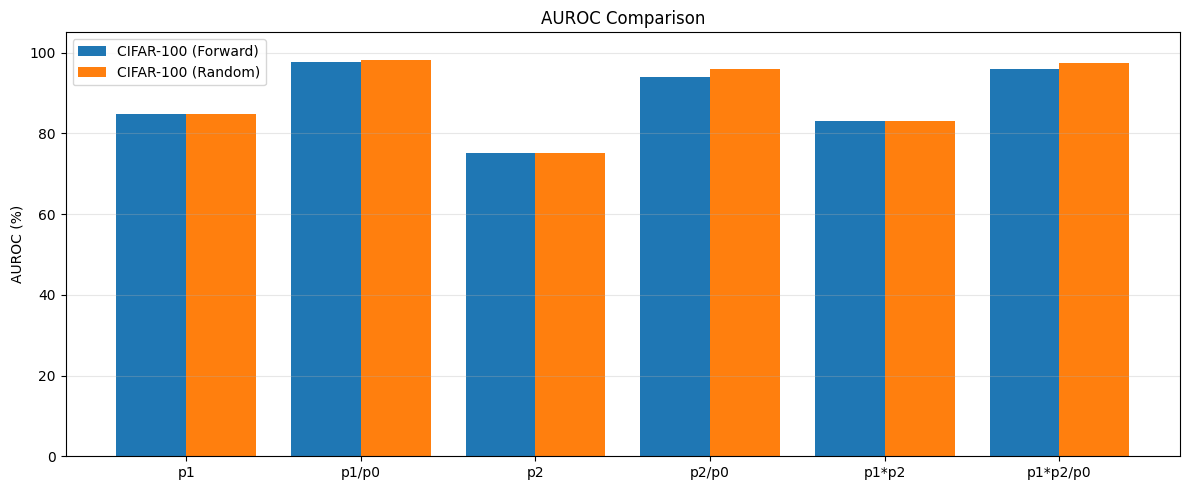

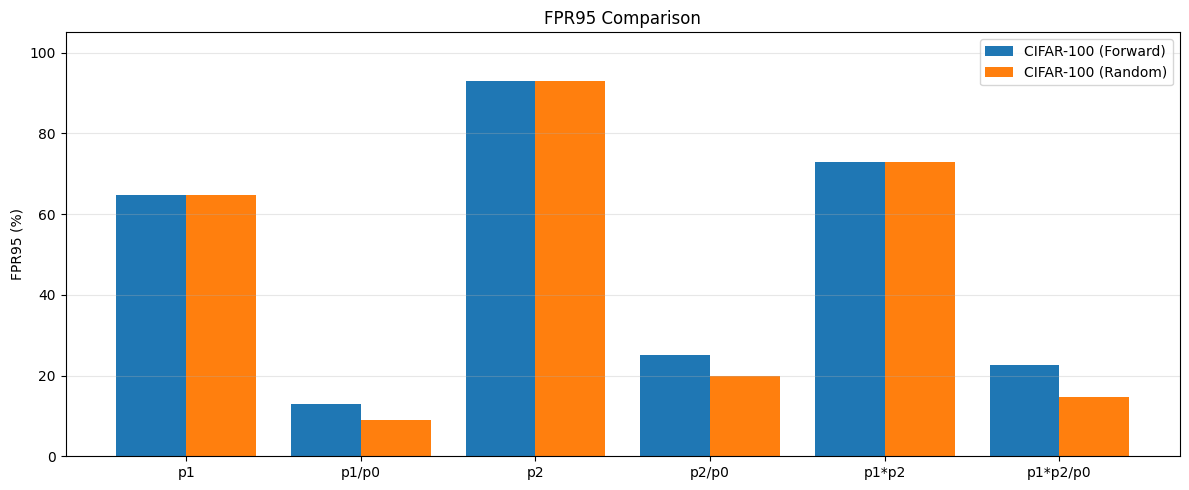

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def plot_experiments(experiments):
    methods = list(next(iter(next(iter(experiments.values())).values())).keys())
    experiment_names = list(experiments.keys())

    metrics = ["AUROC", "FPR95"]

    for metric in metrics:
        x = np.arange(len(methods))
        width = 0.8 / len(experiment_names)

        fig, ax = plt.subplots(figsize=(12, 5))

        for i, (name, result) in enumerate(experiments.items()):
            order = next(iter(result))
            values = [result[order][method][metric] for method in methods]

            ax.bar(
                x + (i - (len(experiment_names) - 1) / 2) * width,
                values,
                width,
                label=name
            )

        ax.set_title(f"{metric} Comparison")
        ax.set_ylabel(f"{metric} (%)")
        ax.set_xticks(x)
        ax.set_xticklabels(methods)
        ax.set_ylim(0, 105)
        ax.legend()
        ax.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

experiments = {
    "CIFAR-100 (Forward)": results_cifar100_forward,
    "CIFAR-100 (Random)": results_cifar100_random
}

plot_experiments(experiments)